# Learn value functions and generalized advantage estimation

This worked reference is validated on CPU. Accelerator compatibility requires a separate source review and target execution receipt. Use the execution matrix to review device selection and data ownership before adapting a separate target program.

- Fit a tabular value function to sampled discounted returns using gamma=0.9 over the finite horizon of at most eight actions, and report its error before and after optimization.
- Compute generalized advantages with a reverse scan over time and an independently hand-calculated multi-step example.
- Use the retained final observation to bootstrap a continuing task cutoff while stopping the trace across episode resets.
- Explain why the existing finite-horizon REINFORCE/PPO objective opts out of time-limit bootstrapping.

For a finite task lasting at most eight actions, how can a tabular critic estimate the expected discounted return with gamma=0.9 from sampled trajectories? We will fit the table to those same discounted targets, then compute GAE with the same discount. At a true terminal there is no bootstrap; a collector cutoff in a continuing task can bootstrap from the final pre-reset observation while stopping the trace.

## The idea

The table minimizes masked squared error to sampled discounted returns G_t = r_t + 0.9 r_(t+1) + ... through the episode end, over at most eight actions. GAE uses gamma=0.9 and lambda=0.95. This critic target matches that discount. The position-only table remains an approximation because position omits remaining time and sampled stochastic returns vary. A lower critic loss describes fit to these targets; by itself it says nothing about policy improvement.

## One retained transition has two observations

A transition records the state used to choose the action and the actual next state returned by `step`. At an external cutoff, the collector may next reset to position 0 even though the cutoff transition ended at position 3; keep that final pre-reset `next_observation` for a continuing-task bootstrap.

Keep four quantities distinct: reward is one transition's $r_t$; return is the future reward sum (here discounted with $\gamma=0.9$); value $V(s)$ is the expected return from a state; advantage estimates how much better this action's outcome was than that state baseline. The fitted four-position table approximates expected discounted return from sampled live rows, so noisy targets and omitted time remaining leave residual error. Padding remains in the fixed array but contributes no loss.

### A cutoff bootstraps value but stops reverse GAE

**Predict:** If the collector cutoff is the task’s true finite deadline, which bootstrap term and advantage values change?

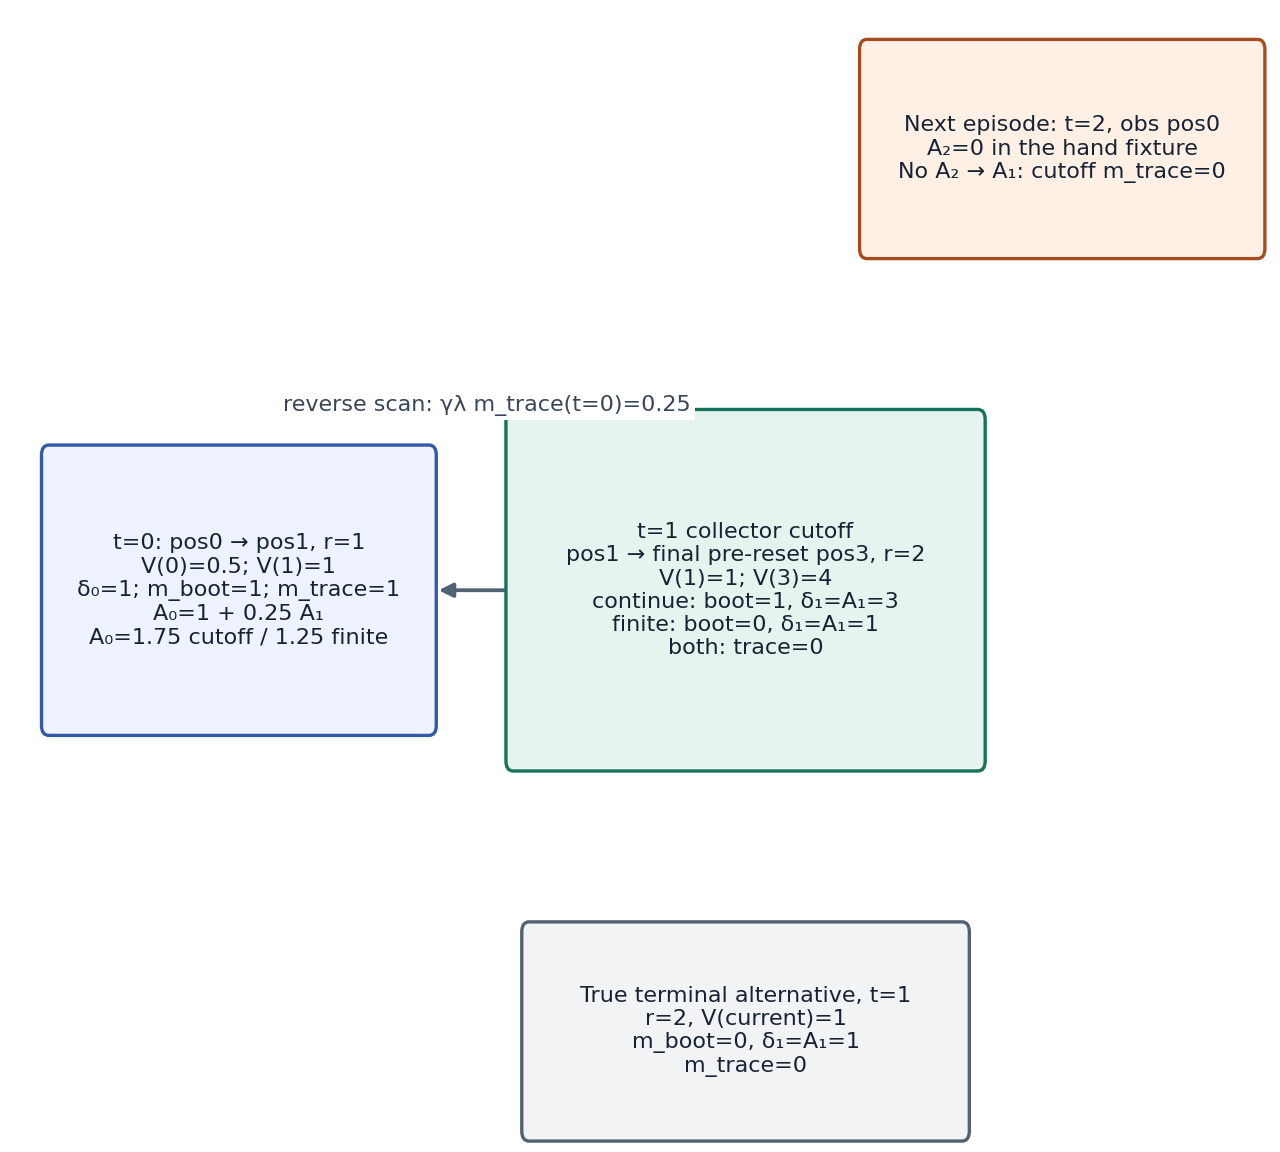

*Deterministic hand fixture with gamma=0.5 and lambda=0.5; the critic loss plot separately uses gamma=0.9 discounted targets.*

Read the graph left to right as $t=0: s_0=0\to s_1=1, r_0=1$ then $t=1: s_1=1\to s_2=3, r_1=2$; the reverse arrow points from the second residual back to the first with coefficient $\gamma\lambda=0.25$. For this diagram only, $\gamma=\lambda=0.5$: continuing cutoff gives $\delta_1=A_1=3$, then $A_0=1.75$; making it the finite deadline removes $\gamma V(3)=2$, giving $\delta_1=1$ and $A_0=1.25$. The trace mask is zero in both cases, isolating reset episode $t=2, s_2=0$. A true terminal also has bootstrap mask zero. Predict which number changes if the collector cutoff is reclassified as the task deadline: the bootstrap contribution changes, while the trace boundary stays closed. The critic-fit plot elsewhere uses gamma=0.9.

### Pause and reason

At a collector cutoff, the next rollout row shows reset position 0 but the transition record says the final observation was position 3. Which observation supplies the bootstrap value?

<details><summary>Compare your reasoning</summary>

Use position 3, the actual transition result retained in `next_observation`. Position 0 is the start of another episode and must not enter the earlier episode's target.

</details>

## Bootstrapping and trace continuation answer different questions

A bootstrap mask answers whether the next state has future value; a trace mask answers whether reverse GAE may carry later residuals across this transition. A true terminal has bootstrap mask 0. A continuing collector cutoff has bootstrap mask 1 from the final pre-reset observation, but trace mask 0 so the next episode cannot leak backward. The finite task's own eight-action deadline has no objective beyond it, so its bootstrap mask is also 0. Reset only after saving the final observation.

$$
\delta_t = r_t + \gamma\,m_t^{\mathrm{boot}} V(s_{t+1}) - V(s_t) \quad A_t = \delta_t + \gamma\lambda\,m_t^{\mathrm{trace}} A_{t+1}
$$

## Work the reverse scan by hand

Use the diagram's separate hand fixture, with $\gamma=0.5$, $\lambda=0.5$, and values $V(0)=0.5$, $V(1)=1$, $V(3)=4$. The first transition has reward 1, so $\delta_0=1+0.5\cdot 1-0.5=1$. The cutoff transition has reward 2: for a continuing collector, $\delta_1=2+0.5\cdot 4-1=3$, and the trace stops at that boundary, so $A_1=3$ and $A_0=1+0.25\cdot 3=1.75$. At a finite deadline, remove the bootstrap term: $\delta_1=1$ and $A_0=1.25$. A reset episode's advantage never flows into this reverse scan. This is not the separate $\gamma=0.9$ critic-fit rollout.

## A lower fit error is evidence of optimization, not policy quality

The critic-fit plot measures masked mean-squared error on gamma=0.9 discounted returns. The four position values cannot encode remaining time, and sampled returns differ, so a decreasing loss need not reach zero. A value estimate is not the realized return; an advantage is a return or TD-based estimate minus a value baseline. Fitting that baseline may reduce policy-gradient estimator variance, but this lesson does not add an actor update. To claim policy improvement, update an actor and evaluate it on held-out episodes.

## Define the rollout and return target

Import the local CPU dependencies, define the fixed-shape collector, and retain each transition’s actual next observation. Add the finite-horizon discounted-return helper with gamma=0.9.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np

def rollout(theta, key, batch_size=512, horizon=8):
    """Collect fixed-shape trajectories and retain each pre-reset next state."""
    reset_key, action_key = jax.random.split(key)
    position = jax.vmap(lambda subkey: jax.random.randint(subkey, (), 0, 2))(jax.random.split(reset_key, batch_size))
    elapsed = jnp.zeros((batch_size,), dtype=jnp.int32)
    done = jnp.zeros((batch_size,), dtype=jnp.bool_)
    time_keys = jax.random.split(action_key, horizon)

    def collect(carry, time_key):
        position, elapsed, done = carry
        observation = position
        active = ~done
        keys = jax.random.split(time_key, batch_size)
        probability = jax.nn.sigmoid(theta[jnp.minimum(position, 2)])
        action = jax.vmap(jax.random.bernoulli)(keys, probability).astype(jnp.int32)
        proposed = jnp.clip(position + 2 * action - 1, 0, 3)
        next_position = jnp.where(active, proposed, position)
        next_elapsed = elapsed + active.astype(jnp.int32)
        terminated = active & (next_position == 3)
        truncated = active & ~terminated & (next_elapsed >= horizon)
        reward = jnp.where(active, jnp.where(terminated, 1., -.01), 0.)
        next_done = done | terminated | truncated
        record = {
            "observation": observation,
            "next_observation": next_position,
            "reward": reward,
            "active": active,
            "terminated": terminated,
            "truncated": truncated,
        }
        return (next_position, next_elapsed, next_done), record

    final_state, records = jax.lax.scan(collect, (position, elapsed, done), time_keys)
    return final_state, records

def discounted_returns_to_go(rewards, gamma):
    """Compute finite-horizon discounted returns along the time axis."""
    discounts = gamma ** jnp.arange(rewards.shape[0], dtype=rewards.dtype)
    weighted = rewards * discounts.reshape((-1,) + (1,) * (rewards.ndim - 1))
    return jnp.cumsum(weighted[::-1], axis=0)[::-1] / discounts.reshape((-1,) + (1,) * (rewards.ndim - 1))

The collector stores `next_observation` before any reset and returns time-major records. No repository module is needed.

## Define and fit the tabular value function

Define a masked mean-squared objective and its gradient-update scan. Padded rows are sanitized before residual arithmetic and do not affect the denominator.

In [2]:
def value_loss(value_table, records, targets):
    """Masked MSE with fixed targets and padding sanitized before arithmetic."""
    active = jnp.asarray(records["active"], dtype=jnp.bool_)
    predictions = value_table[jnp.clip(records["observation"], 0, 3)]
    targets = jax.lax.stop_gradient(jnp.asarray(targets))
    safe_targets = jnp.where(active, targets, jnp.zeros_like(targets))
    residual = jnp.where(active, predictions - safe_targets, jnp.zeros_like(predictions))
    return jnp.sum(jnp.square(residual)) / jnp.maximum(jnp.sum(active), 1)


def fit_value_function(records, targets, updates=250, learning_rate=.1):
    """Fit one scalar per state and retain the initial and updated losses."""
    table = jnp.zeros((4,), dtype=jnp.float32)
    loss_fn = lambda candidate: value_loss(candidate, records, targets)
    initial = loss_fn(table)

    def update(candidate, _):
        _, gradient = jax.value_and_grad(loss_fn)(candidate)
        next_table = candidate - learning_rate * gradient
        return next_table, loss_fn(next_table)

    table, history = jax.lax.scan(update, table, None, length=updates)
    return table, jnp.concatenate((initial[None], history))

The four table entries correspond to positions. The target is fixed rollout reward-to-go; the optimizer changes the table through gradient descent.

## Define GAE and choose the reproducible policy

Implement reverse GAE with separate bootstrap and trace-continuation masks, then set the policy logits used by the example.

In [3]:
def generalized_advantage_estimate(records, value_table, gamma=.9, lam=.95,
                                   bootstrap_on_truncation=False):
    """Reverse GAE; bootstrap mask and trace-continuation mask stay separate."""
    observations = records["observation"]
    next_observations = records["next_observation"]
    active = records["active"].astype(jnp.bool_)
    terminated = records["terminated"].astype(jnp.bool_)
    truncated = records["truncated"].astype(jnp.bool_)
    values = value_table[jnp.clip(observations, 0, 3)]
    next_values = value_table[jnp.clip(next_observations, 0, 3)]
    bootstrap = ~(terminated | (truncated & ~jnp.asarray(bootstrap_on_truncation)))
    delta = records["reward"] + gamma * bootstrap.astype(values.dtype) * next_values - values
    delta = jnp.where(active, delta, 0.)
    next_active = jnp.concatenate((active[1:], jnp.zeros_like(active[:1])), axis=0)
    trace = active & ~(terminated | truncated) & next_active

    def reverse_step(carry, inputs):
        residual, continues = inputs
        advantage = residual + gamma * lam * continues.astype(residual.dtype) * carry
        return advantage, advantage

    reverse_values = jnp.zeros(observations.shape[1:], dtype=values.dtype)
    _, reverse_advantages = jax.lax.scan(
        reverse_step, reverse_values, (delta[::-1], trace[::-1]))
    return jnp.where(active, reverse_advantages[::-1], 0.)

theta = jnp.array([-.7, .3, 1.1])

A terminal or cutoff can stop the trace while a continuing-task cutoff may still bootstrap from its retained final observation. This finite-horizon example selects no bootstrap beyond its deadline.

## Collect a rollout and fit values

Collect seed 313 data, compute return targets, fit the table for 250 updates, and retain the full loss history.

In [4]:
_, rollout_records = rollout(theta, jax.random.key(313), batch_size=512, horizon=8)
targets = discounted_returns_to_go(rollout_records["reward"], gamma=.9)

value_table, loss_history = fit_value_function(rollout_records, targets)

print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))

initial / final masked value MSE: 0.3257838487625122 0.13587723672389984
fitted V(position 0..3): [0.1953 0.4592 0.8403 0.    ]


Both the initial and updated errors are retained so the exercise can inspect actual learning rather than a hard-coded expected answer.

## Estimate GAE and prepare the learning plot

Estimate advantages with the finite-horizon setting, check their shape and finiteness, and build plot data from the retained loss history.

In [5]:
advantages = generalized_advantage_estimate(
    rollout_records, value_table, gamma=.9, lam=.95,
    bootstrap_on_truncation=False)
print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))
print("GAE shape:", advantages.shape, "all finite:", bool(jnp.all(jnp.isfinite(advantages))))

visual_data = {
    "kind": "line",
    "x": list(range(len(loss_history))),
    "xlabel": "gradient updates",
    "ylabel": "masked value prediction MSE",
    "series": [{"label": "sampled rollout targets, seed 313", "y": np.asarray(loss_history).tolist()}],
}

initial / final masked value MSE: 0.3257838487625122 0.13587723672389984
fitted V(position 0..3): [0.1953 0.4592 0.8403 0.    ]
GAE shape: (8, 512) all finite: True


Every plotted point is a measured masked-MSE value from this run. The four-state critic and finite corridor do not demonstrate actor improvement or continuous control.

## Run the example

In [6]:
"""Self-contained CPU example: tabular value fitting and masked GAE."""

import jax
import jax.numpy as jnp
import numpy as np

def rollout(theta, key, batch_size=512, horizon=8):
    """Collect fixed-shape trajectories and retain each pre-reset next state."""
    reset_key, action_key = jax.random.split(key)
    position = jax.vmap(lambda subkey: jax.random.randint(subkey, (), 0, 2))(jax.random.split(reset_key, batch_size))
    elapsed = jnp.zeros((batch_size,), dtype=jnp.int32)
    done = jnp.zeros((batch_size,), dtype=jnp.bool_)
    time_keys = jax.random.split(action_key, horizon)

    def collect(carry, time_key):
        position, elapsed, done = carry
        observation = position
        active = ~done
        keys = jax.random.split(time_key, batch_size)
        probability = jax.nn.sigmoid(theta[jnp.minimum(position, 2)])
        action = jax.vmap(jax.random.bernoulli)(keys, probability).astype(jnp.int32)
        proposed = jnp.clip(position + 2 * action - 1, 0, 3)
        next_position = jnp.where(active, proposed, position)
        next_elapsed = elapsed + active.astype(jnp.int32)
        terminated = active & (next_position == 3)
        truncated = active & ~terminated & (next_elapsed >= horizon)
        reward = jnp.where(active, jnp.where(terminated, 1., -.01), 0.)
        next_done = done | terminated | truncated
        record = {
            "observation": observation,
            "next_observation": next_position,
            "reward": reward,
            "active": active,
            "terminated": terminated,
            "truncated": truncated,
        }
        return (next_position, next_elapsed, next_done), record

    final_state, records = jax.lax.scan(collect, (position, elapsed, done), time_keys)
    return final_state, records

def discounted_returns_to_go(rewards, gamma):
    """Compute finite-horizon discounted returns along the time axis."""
    discounts = gamma ** jnp.arange(rewards.shape[0], dtype=rewards.dtype)
    weighted = rewards * discounts.reshape((-1,) + (1,) * (rewards.ndim - 1))
    return jnp.cumsum(weighted[::-1], axis=0)[::-1] / discounts.reshape((-1,) + (1,) * (rewards.ndim - 1))

def value_loss(value_table, records, targets):
    """Masked MSE with fixed targets and padding sanitized before arithmetic."""
    active = jnp.asarray(records["active"], dtype=jnp.bool_)
    predictions = value_table[jnp.clip(records["observation"], 0, 3)]
    targets = jax.lax.stop_gradient(jnp.asarray(targets))
    safe_targets = jnp.where(active, targets, jnp.zeros_like(targets))
    residual = jnp.where(active, predictions - safe_targets, jnp.zeros_like(predictions))
    return jnp.sum(jnp.square(residual)) / jnp.maximum(jnp.sum(active), 1)


def fit_value_function(records, targets, updates=250, learning_rate=.1):
    """Fit one scalar per state and retain the initial and updated losses."""
    table = jnp.zeros((4,), dtype=jnp.float32)
    loss_fn = lambda candidate: value_loss(candidate, records, targets)
    initial = loss_fn(table)

    def update(candidate, _):
        _, gradient = jax.value_and_grad(loss_fn)(candidate)
        next_table = candidate - learning_rate * gradient
        return next_table, loss_fn(next_table)

    table, history = jax.lax.scan(update, table, None, length=updates)
    return table, jnp.concatenate((initial[None], history))

def generalized_advantage_estimate(records, value_table, gamma=.9, lam=.95,
                                   bootstrap_on_truncation=False):
    """Reverse GAE; bootstrap mask and trace-continuation mask stay separate."""
    observations = records["observation"]
    next_observations = records["next_observation"]
    active = records["active"].astype(jnp.bool_)
    terminated = records["terminated"].astype(jnp.bool_)
    truncated = records["truncated"].astype(jnp.bool_)
    values = value_table[jnp.clip(observations, 0, 3)]
    next_values = value_table[jnp.clip(next_observations, 0, 3)]
    bootstrap = ~(terminated | (truncated & ~jnp.asarray(bootstrap_on_truncation)))
    delta = records["reward"] + gamma * bootstrap.astype(values.dtype) * next_values - values
    delta = jnp.where(active, delta, 0.)
    next_active = jnp.concatenate((active[1:], jnp.zeros_like(active[:1])), axis=0)
    trace = active & ~(terminated | truncated) & next_active

    def reverse_step(carry, inputs):
        residual, continues = inputs
        advantage = residual + gamma * lam * continues.astype(residual.dtype) * carry
        return advantage, advantage

    reverse_values = jnp.zeros(observations.shape[1:], dtype=values.dtype)
    _, reverse_advantages = jax.lax.scan(
        reverse_step, reverse_values, (delta[::-1], trace[::-1]))
    return jnp.where(active, reverse_advantages[::-1], 0.)

theta = jnp.array([-.7, .3, 1.1])

_, rollout_records = rollout(theta, jax.random.key(313), batch_size=512, horizon=8)
targets = discounted_returns_to_go(rollout_records["reward"], gamma=.9)

value_table, loss_history = fit_value_function(rollout_records, targets)

print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))

advantages = generalized_advantage_estimate(
    rollout_records, value_table, gamma=.9, lam=.95,
    bootstrap_on_truncation=False)
print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))
print("GAE shape:", advantages.shape, "all finite:", bool(jnp.all(jnp.isfinite(advantages))))

visual_data = {
    "kind": "line",
    "x": list(range(len(loss_history))),
    "xlabel": "gradient updates",
    "ylabel": "masked value prediction MSE",
    "series": [{"label": "sampled rollout targets, seed 313", "y": np.asarray(loss_history).tolist()}],
}


initial / final masked value MSE: 0.3257838487625122 0.13587723672389984
fitted V(position 0..3): [0.1953 0.4592 0.8403 0.    ]
initial / final masked value MSE: 0.3257838487625122 0.13587723672389984
fitted V(position 0..3): [0.1953 0.4592 0.8403 0.    ]
GAE shape: (8, 512) all finite: True


Expected: A four-entry value table, its retained masked-MSE history, and time-major GAE advantages from one sampled finite-horizon rollout.

## Value error falls while the table learns sampled returns

Predict: Will the error reach zero, and does a decreasing critic loss prove that the policy improved?

CPU computation; rerun to recompute the data.

Run the cells below to produce the figure, then follow the walkthrough beneath it.

In [7]:
visual_data = {'kind':'line','x':list(range(len(loss_history))),'xlabel':'gradient updates','ylabel':'masked value prediction MSE','series':[{'label':'sampled rollout, seed 313','y':np.asarray(loss_history).tolist()}]}

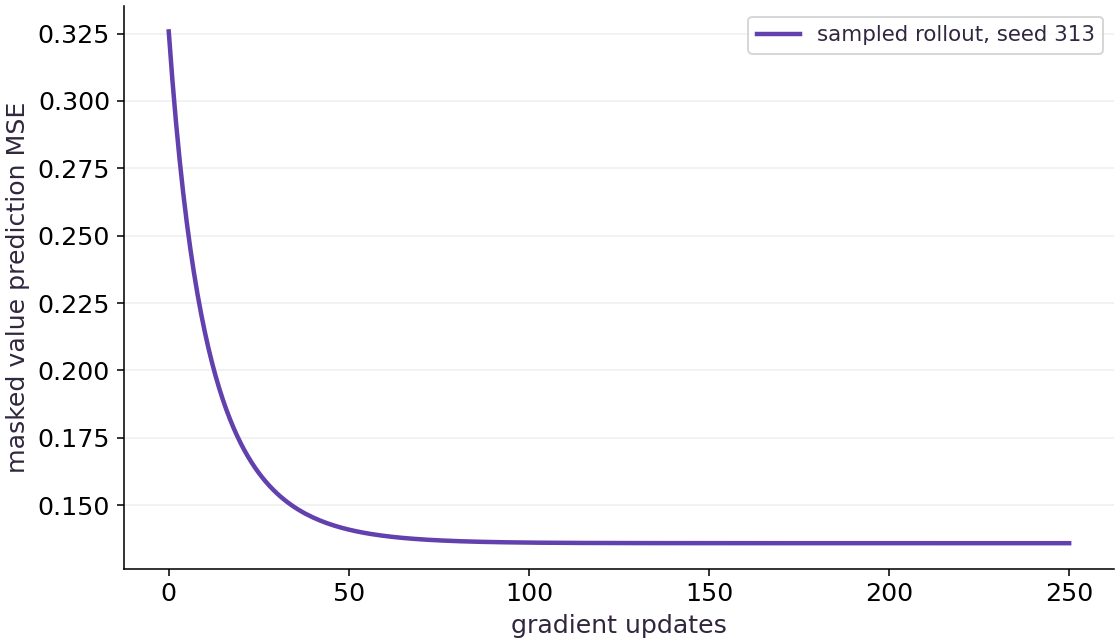

In [8]:
# Render the figure from the data computed above. Change the data experiment and rerun.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 13, 'axes.labelcolor': '#30273e', 'text.color': '#30273e'})
def draw_panel(ax, data):
    import numpy as np
    palette = ['#6240ad', '#087c83', '#bc532c', '#405d9d']
    kind = data['kind']
    if kind in ('heatmap', 'field'):
        a = np.asarray(data['values'], dtype=float)
        assert a.ndim == 2 and np.isfinite(a).all()
        kw = {'cmap': 'PuOr' if data.get('diverging') else 'Purples', 'aspect': 'auto'}
        if kind == 'field':
            kw.update(extent=data['extent'], origin='lower', vmin=0, vmax=1)
        elif data.get('diverging'):
            limit = max(float(np.abs(a).max()), 1e-10)
            kw.update(vmin=-limit, vmax=limit)
        if data.get('scale') == 'probability' or data['unit'] in ('attention weight', 'next-token probability', 'masked-token probability'):
            kw.update(vmin=0, vmax=1)
        categorical = data.get('scale') == 'categorical' or any(name in data['unit'] for name in ('device ID','program ID'))
        if categorical:
            from matplotlib.colors import ListedColormap, BoundaryNorm
            from matplotlib import colormaps
            ids=np.unique(a).astype(int)
            boundaries=np.r_[ids[0]-.5,(ids[:-1]+ids[1:])/2,ids[-1]+.5]
            kw.update(cmap=ListedColormap([colormaps['tab20'](i) for i in range(len(ids))]), norm=BoundaryNorm(boundaries,len(ids)))
        im = ax.imshow(a, **kw)
        ax.figure.colorbar(im, ax=ax, shrink=0.8, label=data['unit'], **({'ticks':ids} if categorical else {}))
        if kind == 'heatmap':
            if a.size <= 32:
                mid = (float(a.min()) + float(a.max())) / 2
                for (i, j), value in np.ndenumerate(a):
                    rgb=im.cmap(im.norm(value))[:3]
                    luminance=sum(c*w for c,w in zip(rgb,[0.2126,0.7152,0.0722]))
                    ax.text(j, i, f'{value:.3g}', ha='center', va='center', fontsize=11,
                            color='white' if luminance < 0.5 else '#20202c')
            ax.set_xticks(range(a.shape[1]), data.get('columns', [str(i) for i in range(a.shape[1])]))
            ax.set_yticks(range(a.shape[0]), data.get('rows', [str(i) for i in range(a.shape[0])]))
            if a.shape[1] > 5: ax.tick_params(axis='x', labelsize=11)
        else:
            pts = np.asarray(data['points']); labels = np.asarray(data['labels'])
            for label, marker in [(0, 'o'), (1, '^')]:
                selected = pts[labels == label]
                ax.scatter(selected[:, 0], selected[:, 1], label=f'observed label {label}', marker=marker,
                           s=38, facecolors='white' if label == 0 else '#f4b547', edgecolors='#272238', linewidths=1)
            ax.legend(loc='upper left', fontsize=10)
    elif kind in ('line', 'bar'):
        series = data['series']
        x = np.asarray(data.get('x', list(range(len(data.get('labels', []))))))
        assert len(x) and np.isfinite(x).all()
        for i, s in enumerate(series):
            y = np.asarray(s['y'], dtype=float)
            assert y.shape == x.shape and np.isfinite(y).all(), s['label']
            if data.get('yscale') == 'log': assert (y > 0).all()
            if kind == 'line':
                ax.plot(x, y, color=palette[i % len(palette)], label=s['label'], linewidth=2.3,
                        linestyle=['-', '--', '-.', ':'][i % 4], marker='o' if len(x) <= 25 else None, markersize=3)
            else:
                width = 0.78 / len(series)
                bars = ax.bar(x + (i - (len(series)-1)/2)*width, y, width, label=s['label'], color=palette[i % len(palette)])
                if len(x)*len(series) <= 12: ax.bar_label(bars, fmt='%.3g', fontsize=10, padding=3)
        if kind == 'bar':
            ax.set_xticks(x, data['labels'])
            ax.margins(y=0.17)
            if any(len(t) > 13 for t in data['labels']): ax.tick_params(axis='x', labelrotation=15, labelsize=11)
        if data.get('xscale'): ax.set_xscale(data['xscale'])
        if data.get('yscale'): ax.set_yscale(data['yscale'], **({'linthresh':data.get('linthresh',2)} if data['yscale']=='symlog' else {}))
        for marker in data.get('markers',[]):
            ax.scatter([marker['x']],[marker['y']],color='#bc532c',s=45,zorder=5)
            ax.annotate(marker['label'],(marker['x'],marker['y']),xytext=(-85,12),textcoords='offset points',fontsize=10)
        for boundary in data.get('boundaries', []): ax.axvline(boundary, color='#716e7b', linestyle=':', linewidth=1)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(fontsize=11, loc='best')
    elif kind == 'table':
        headers = data['headers']
        rows = data['rows']
        assert headers and rows and all(len(row) == len(headers) for row in rows)
        ax.axis('off')
        table = ax.table(cellText=rows, colLabels=headers, cellLoc='center',
                         loc='center', colWidths=data.get('widths'))
        table.auto_set_font_size(False)
        table.set_fontsize(11)
        table.scale(1, 2.7)
        for (row, _), cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row == 0 else ('#f4f7fb' if row % 2 else '#ffffff'))
            cell.set_text_props(color='#172334', weight='bold' if row == 0 else 'normal')
    elif kind == 'vectors':
        for i, arrow in enumerate(data['arrows']):
            start = np.asarray(arrow['start']); end = np.asarray(arrow['end'])
            ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->','color':palette[i], 'lw':2.8})
            mid=(start+end)/2
            ax.annotate(arrow['label'], mid, xytext=(7,7), textcoords='offset points', color=palette[i])
        ax.set(xlim=(-0.7,4.5),ylim=(-0.7,5),xlabel='first coordinate',ylabel='second coordinate')
        ax.set_aspect('equal'); ax.grid(alpha=0.2)
    elif kind == 'flow':
        from matplotlib.patches import FancyBboxPatch
        nodes=data['nodes']; ax.set(xlim=(0,1),ylim=(0,len(nodes))); ax.axis('off')
        if data.get('layout') == 'merge':
            import textwrap
            for i,label in enumerate(nodes[:3]):
                x=0.02+i*0.33
                ax.add_patch(FancyBboxPatch((x,3.7),0.29,1.0,boxstyle='round,pad=0.015',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(x+0.145,4.2,textwrap.fill(label,20),ha='center',va='center',fontsize=11)
                ax.annotate('',(0.5,2.8),(x+0.145,3.67),arrowprops={'arrowstyle':'->','color':'#6240ad'})
            for y,label in [(2.4,nodes[3]),(0.9,nodes[4])]:
                ax.add_patch(FancyBboxPatch((0.08,y-0.35),0.84,0.7,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
            ax.annotate('',(0.5,1.3),(0.5,2.0),arrowprops={'arrowstyle':'->','color':'#6240ad'})
        else:
            for i, label in enumerate(nodes):
                y=len(nodes)-i-0.5
                ax.add_patch(FancyBboxPatch((0.08,y-0.3),0.84,0.6,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
                if i<len(nodes)-1: ax.annotate('',(0.5,y-0.67),(0.5,y-0.32),arrowprops={'arrowstyle':'->','color':'#6240ad'})
    else: raise ValueError(f'Unknown figure kind: {kind}')
    if data.get('xlabel'): ax.set_xlabel(data['xlabel'])
    if data.get('ylabel'): ax.set_ylabel(data['ylabel'])
    if data.get('title'): ax.set_title(data['title'], loc='left', fontsize=12, pad=12)
    for spine in ('top','right'): ax.spines[spine].set_visible(False)


def draw_mechanism(ax, diagram):
    """Draw a source-authored conceptual/analytic mechanism, never measured data."""
    import numpy as np
    from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Ellipse
    panel = diagram['panel']
    kind = panel['kind']
    colors = {'data':('#eef3ff','#3559a8'), 'state':('#f0eafa','#6240ad'),
              'fixed':('#f1f3f5','#536273'), 'result':('#e5f4ee','#17735c'),
              'warning':('#fff0e6','#a64d20')}
    if kind == 'graph':
        ax.set(xlim=(0,panel.get('width',10)),ylim=(panel.get('height',8),0))
        ax.axis('off')
        nodes={node['id']:node for node in panel['nodes']}
        for edge in panel['edges']:
            a,b=nodes[edge['from']],nodes[edge['to']]
            side_a=edge.get('exit','bottom'); side_b=edge.get('enter','top')
            def port(node,side):
                x,y=node['x'],node['y']; w,h=node.get('w',3),node.get('h',.8)
                return {'top':(x,y-h/2),'bottom':(x,y+h/2),'left':(x-w/2,y),'right':(x+w/2,y)}[side]
            start,end=port(a,side_a),port(b,side_b)
            ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'-|>','color':'#536273','lw':1.7,'connectionstyle':edge.get('curve','arc3,rad=0')},zorder=1)
            if edge.get('label'):
                tx,ty=edge.get('labelAt',((start[0]+end[0])/2,(start[1]+end[1])/2))
                ax.text(tx,ty,edge['label'],ha='center',va='center',fontsize=10,color='#394658',bbox={'facecolor':'white','edgecolor':'none','pad':2},zorder=4)
        for node in panel['nodes']:
            fill,stroke=colors[node.get('tone','data')]
            x,y=node['x'],node['y'];w,h=node.get('w',3),node.get('h',.8)
            ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=0.02,rounding_size=0.07',facecolor=fill,edgecolor=stroke,lw=1.5,zorder=2))
            ax.text(x,y,node['label'],ha='center',va='center',fontsize=node.get('fontSize',12),color='#172334',zorder=3)
    elif kind == 'table':
        ax.axis('off')
        table=ax.table(cellText=panel['rows'],colLabels=panel['headers'],cellLoc='center',loc='center',colWidths=panel.get('widths'))
        table.auto_set_font_size(False);table.set_fontsize(12);table.scale(1,2.7)
        for (row,col),cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row==0 else ('#f4f7fb' if row%2 else '#ffffff'))
            cell.set_text_props(color='#172334',weight='bold' if row==0 else 'normal')
    elif kind == 'clipping':
        ax.add_patch(Circle((0,0),2.5,fill=False,edgecolor='#17735c',linestyle='--',lw=1.8))
        ax.add_patch(Rectangle((-2.5,-2.5),5,5,fill=False,edgecolor='#a64d20',linestyle=':',lw=1.8))
        for end,color,label,offset in [((3,4),'#3559a8','Original (3, 4)',(8,5)),((1.5,2),'#17735c','Norm clip (1.5, 2)',(-126,-16)),((2.5,2.5),'#a64d20','Coordinate clip (2.5, 2.5)',(8,-2))]:
            ax.annotate('',xy=end,xytext=(0,0),arrowprops={'arrowstyle':'-|>','color':color,'lw':2.6})
            ax.annotate(label,end,xytext=offset,textcoords='offset points',color=color,fontsize=11)
        ax.set(xlim=(-3,5.8),ylim=(-3,4.8),xlabel='gradient coordinate 1',ylabel='gradient coordinate 2')
        ax.set_aspect('equal');ax.grid(alpha=.15)
    elif kind == 'patches':
        ax.set(xlim=(-.1,4.1),ylim=(4.1,-.1));ax.set_aspect('equal');ax.axis('off')
        for i in range(4):
            x,y=(i%2)*2,(i//2)*2
            visible=i in [0,3]
            ax.add_patch(Rectangle((x,y),2,2,facecolor='#e5f4ee' if visible else '#fff0e6',edgecolor='#17735c' if visible else '#a64d20',hatch=None if visible else '///',lw=2))
            ax.text(x+1,y+1,f'Patch {i}\n'+('visible input' if visible else 'hidden target'),ha='center',va='center',fontsize=14,bbox={'facecolor':'white','edgecolor':'none','alpha':.94,'pad':5})
        for a in [1,3]:
            ax.axhline(a,color='#172334',alpha=.25,lw=.7);ax.axvline(a,color='#172334',alpha=.25,lw=.7)
    elif kind == 'receptive-field':
        ax.set(xlim=(-.15,5.15),ylim=(5.15,-.15));ax.set_aspect('equal');ax.axis('off')
        for row in range(5):
            for col in range(5):
                selected=1<=row<=3 and 1<=col<=3
                ax.add_patch(Rectangle((col,row),1,1,facecolor='#e9e4f5' if selected else '#f4f7fb',edgecolor='#a6afc1',lw=1))
                ax.text(col+.5,row+.5,f'{row},{col}',ha='center',va='center',fontsize=12)
        ax.add_patch(Rectangle((1,1),3,3,fill=False,edgecolor='#6240ad',lw=3))
        ax.set_title('One 3 × 3 receptive field inside a 5 × 5 input',fontsize=13,pad=12)
    elif kind == 'covariance':
        for covariance,color,label in [(np.array([[1,.8],[.8,1]]),'#6240ad','Correlated covariance'),(np.eye(2),'#17735c','Same marginals, zero covariance')]:
            eig,vec=np.linalg.eigh(covariance);order=np.argsort(eig)[::-1];eig=eig[order];vec=vec[:,order]
            angle=np.degrees(np.arctan2(vec[1,0],vec[0,0]))
            ax.add_patch(Ellipse((0,0),2*np.sqrt(eig[0]),2*np.sqrt(eig[1]),angle=angle,fill=False,lw=2.5,edgecolor=color,label=label))
        ax.set(xlim=(-1.8,1.8),ylim=(-1.8,1.8),xlabel='first variable',ylabel='second variable')
        ax.set_aspect('equal');ax.grid(alpha=.2);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),fontsize=10)
    elif kind == 'timeline':
        ax.set(xlim=(0,10),ylim=(-.7,2.7),yticks=[0,1,2],yticklabels=['Host','Device','Measurement'])
        for start,length,y,label,color in [(0,1,0,'dispatch','#3559a8'),(1,6,1,'device work','#6240ad'),(1,6,0,'wait for result','#a64d20'),(0,7,2,'completed-result interval','#17735c')]:
            ax.barh(y,length,left=start,height=.45,color=color,alpha=.18)
            ax.text(start+length/2,y,label,ha='center',va='center',fontsize=11)
        ax.axvline(7,color='#536273',linestyle='--');ax.text(7.1,.5,'result ready',fontsize=11)
        ax.set_xlabel('conceptual order; lengths are not measured durations')
        ax.invert_yaxis()
    else:
        raise ValueError(f'Unknown mechanism kind: {kind}')

panels = visual_data.get('panels', [visual_data])
fig, axes = plt.subplots(len(panels), 1, figsize=(8, 4.6 * len(panels)), squeeze=False, layout='constrained')
for ax, panel in zip(axes[:, 0], panels):
    draw_panel(ax, panel)
plt.show()

### Read the figure

The x-axis is value-table gradient update; the y-axis is masked mean-squared error on 512 retained episodes (seed 313). For discounted targets with $\gamma=0.9$, the plotted training error falls from about 0.3258 to 0.1359. Compare the first and last points to predict the direction of change; the remaining error is plausible because the four-entry position table omits time remaining and sampled returns vary. This curve measures critic fit, not episode return or policy quality.

### Connect it to the computation

Each plotted point is produced by `fit_value_function` on the retained rollout and its gamma=0.9 targets. The separate hand-computed diagram uses gamma=0.5 and lambda=0.5 to expose bootstrap and trace masks; do not transfer its numerical advantages to this plot. Lower fit error says the table follows its training targets more closely, not that an actor improved. The existing policy objectives and exact-return evaluation remain separate.

## Match value targets to the GAE discount

Predict: For rewards [1,1], gamma=0.9, and terminal V=0, compare TD residuals for undiscounted values [2,1,0] and discounted values [1.9,1,0]. What residual does a continuing-task cutoff produce when reward=2, current V=1, and final pre-reset V=4?

In [9]:
gamma = .9
rewards = np.array([1., 1.])
undiscounted_v = np.array([2., 1., 0.])
discounted_v = np.array([1.9, 1., 0.])
undiscounted_delta = rewards[0] + gamma * undiscounted_v[1] - undiscounted_v[0]
discounted_delta = rewards[0] + gamma * discounted_v[1] - discounted_v[0]
terminal_delta = rewards[1] + gamma * 0. - discounted_v[1]
cutoff_delta = 2. + gamma * 4. - 1.
np.testing.assert_allclose([undiscounted_delta, terminal_delta], [-.1, 0.])
np.testing.assert_allclose([discounted_delta, terminal_delta], [0., 0.])
np.testing.assert_allclose(cutoff_delta, 4.6)
print("undiscounted / matched / terminal / continuing-cutoff:", [undiscounted_delta, discounted_delta, terminal_delta, cutoff_delta])

undiscounted / matched / terminal / continuing-cutoff: [np.float64(-0.10000000000000009), np.float64(0.0), np.float64(0.0), 4.6]


Expected: Undiscounted-target residuals [-0.1, 0]; matched discounted-target residuals [0, 0]; continuing cutoff residual 4.6. A true terminal uses zero bootstrap.

The TD target uses the same gamma as the value objective. At a true terminal the bootstrap is zero. At an external cutoff of a continuing task, use the retained final pre-reset value; the GAE trace still stops at that boundary.

## Predict the time-limit target

Predict: If gamma is 0.5, reward is 2, V(position 1)=1 and the final pre-reset observation is position 3 with value 4, what is the TD residual?

In [10]:
gamma = .5
reward, current_value, final_value = 2., 1., 4.
delta = reward + gamma * final_value - current_value
assert delta == 3.
print('cutoff residual:', delta)

cutoff residual: 3.0


Expected: cutoff residual: 3.0

The old episode's final observation supplies the next value. The reset state in the following row is excluded from this transition.

## Train the value table on a retained rollout

Predict: Will fitting four shared state values drive error to zero when targets are sampled returns?

In [11]:
_, value_records = rollout(jnp.array([-.7,.3,1.1]), jax.random.key(313), 512, 8)
value_targets = discounted_returns_to_go(value_records['reward'], gamma=.9)
value_table, value_history = fit_value_function(value_records, value_targets, 250, .1)
assert value_history[-1] < value_history[0] * .7
print('initial / final MSE:', float(value_history[0]), float(value_history[-1]))
print('V table:', np.asarray(value_table).round(4).tolist())

initial / final MSE: 0.3257838487625122 0.13587723672389984
V table: [0.19529999792575836, 0.459199994802475, 0.8403000235557556, 0.0]


Expected: CPU JAX 0.9.2, seed 313: initial MSE 0.325784; final MSE 0.135877; fitted values [0.1953, 0.4592, 0.8403, 0.0].

The loss falls through gradient updates on actual sampled episodes. It remains positive because a four-state table cannot predict the stochastic return of every individual trajectory.

## Your exercise

The task lasts at most eight actions and the value target is discounted return with gamma=0.9, matching GAE gamma. Change the collection key from 313 to 314. Before running, predict which of the fitted values and final MSE should remain identical. Then retain both error histories and explain why changed trajectories should change the fitted table.

### How to write this exercise — Step-by-step recipe & starter scaffold

**Inputs:**
- A policy, an explicit collection key, and a retained rollout with `observation`, `next_observation`, and `active`.
- A changed collection key 314 after the recorded seed 313 run.
- The gamma=0.9 discounted-return and value-fit functions.

**Outputs:**
- The fitted four-state value table and initial/per-update masked-MSE history for discounted targets.
- A comparison that keeps both seed-specific fits visible.

**Invariants to check:**
- Only active transitions contribute to value loss.
- The value target discounts rewards with gamma=0.9, the same discount used by GAE.
- The fit uses sampled rollout targets and reports real optimization error.
- Different collection keys can produce different trajectories and fitted values.

**Hints:**
- Build targets from the collected reward array.
- Use gamma=.9 in both the discounted return targets and the GAE call.
- Keep the retained `next_observation` for the later GAE step.
- Compare final errors without expecting stochastic targets to produce zero error.

**Starter code scaffold (fill in the TODOs):**

```python
import jax
import jax.numpy as jnp

def fit_changed_rollout(theta, seed, rollout, discounted_returns_to_go, fit_value_function):
    # TODO: collect a new rollout using the supplied seed
    final_state, records = ...
    # TODO: form targets and fit the state-value table
    targets = ...
    value_table, loss_history = ...
    # TODO: return the learned table and retained error history
    raise NotImplementedError
```

In [12]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference solution

Try your own implementation first.

In [13]:
# Refit from a changed collection key and retain both complete learning records.
seed313_records = rollout_records
seed313_targets = targets
seed313_table = value_table
seed313_history = loss_history
seed314_final_state, seed314_records = rollout(
    theta, jax.random.key(314), batch_size=512, horizon=8
)
seed314_targets = discounted_returns_to_go(seed314_records["reward"], gamma=.9)
seed314_table, seed314_history = fit_value_function(
    seed314_records, seed314_targets, updates=250, learning_rate=.1
)


def independent_numpy_masked_mse(table, records, target_values):
    active = np.asarray(records["active"], dtype=bool)
    observation = np.asarray(records["observation"], dtype=np.int64)
    prediction = np.asarray(table)[np.clip(observation, 0, 3)]
    target_values = np.asarray(target_values)
    safe_targets = np.where(active, target_values, 0.0)
    residual = np.where(active, prediction - safe_targets, 0.0)
    return float(np.square(residual).sum() / max(int(active.sum()), 1))


# Independently audit the initial zero table and the returned fitted table for each seed.
for records, targets_for_run, table, history in (
    (seed313_records, seed313_targets, seed313_table, seed313_history),
    (seed314_records, seed314_targets, seed314_table, seed314_history),
):
    initial_numpy_mse = independent_numpy_masked_mse(
        np.zeros((4,), dtype=np.float32), records, targets_for_run
    )
    final_numpy_mse = independent_numpy_masked_mse(table, records, targets_for_run)
    np.testing.assert_allclose(initial_numpy_mse, float(history[0]), rtol=1e-6, atol=1e-7)
    np.testing.assert_allclose(final_numpy_mse, float(history[-1]), rtol=1e-6, atol=1e-7)
    assert float(history[-1]) < float(history[0])

assert not np.array_equal(
    np.asarray(seed313_records["observation"]),
    np.asarray(seed314_records["observation"]),
)
assert not np.allclose(np.asarray(seed313_table), np.asarray(seed314_table))
print("seed 313 initial/final MSE:", float(seed313_history[0]), float(seed313_history[-1]))
print("seed 313 fitted table:", np.asarray(seed313_table).round(4).tolist())
print("seed 314 initial/final MSE:", float(seed314_history[0]), float(seed314_history[-1]))
print("seed 314 fitted table:", np.asarray(seed314_table).round(4).tolist())

# Exact two-transition discount-mismatch example and boundary bootstrap check.
gamma = .9
rewards_np = np.array([1., 1.])
undiscounted_v = np.array([2., 1., 0.])
discounted_v = np.array([1.9, 1., 0.])
undiscounted_deltas = np.array([
    rewards_np[0] + gamma * undiscounted_v[1] - undiscounted_v[0],
    rewards_np[1] + gamma * undiscounted_v[2] - undiscounted_v[1],
])
matched_deltas = np.array([
    rewards_np[0] + gamma * discounted_v[1] - discounted_v[0],
    rewards_np[1] + gamma * discounted_v[2] - discounted_v[1],
])
np.testing.assert_allclose(undiscounted_deltas, [-.1, 0.])
np.testing.assert_allclose(matched_deltas, [0., 0.])
terminal_delta = 2. + gamma * 0. - 1.
continuing_cutoff_delta = 2. + gamma * 4. - 1.
np.testing.assert_allclose([terminal_delta, continuing_cutoff_delta], [1., 4.6])
terminal_records = {
    "observation": jnp.array([[1]], dtype=jnp.int32),
    "next_observation": jnp.array([[3]], dtype=jnp.int32),
    "reward": jnp.array([[2.]]),
    "active": jnp.array([[True]]),
    "terminated": jnp.array([[True]]),
    "truncated": jnp.array([[False]]),
}
terminal_advantage = generalized_advantage_estimate(
    terminal_records, jnp.array([.5, 1., 2., 4.]), gamma=.9, lam=.95,
    bootstrap_on_truncation=True
)
np.testing.assert_allclose(np.asarray(terminal_advantage), [[1.]], atol=1e-6)

# Hand-check a two-transition episode followed by a reset observation.
hand_table = jnp.array([.5, 1., 2., 4.])
hand_records = {
    "observation": jnp.array([[0], [1], [0]], dtype=jnp.int32),
    "next_observation": jnp.array([[1], [3], [1]], dtype=jnp.int32),
    "reward": jnp.array([[1.], [2.], [0.]]),
    "active": jnp.array([[True], [True], [True]]),
    "terminated": jnp.array([[False], [False], [False]]),
    "truncated": jnp.array([[False], [True], [False]]),
}
continuing_cutoff_advantages = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
np.testing.assert_allclose(
    np.asarray(continuing_cutoff_advantages[:, 0]), np.array([1.75, 3., 0.]), atol=1e-6
)
reset_used_as_bootstrap = {
    **hand_records,
    "next_observation": hand_records["next_observation"].at[1, 0].set(0),
}
wrong_reset_advantages = generalized_advantage_estimate(
    reset_used_as_bootstrap, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
assert not np.allclose(
    np.asarray(wrong_reset_advantages[:2]), np.asarray(continuing_cutoff_advantages[:2])
)
finite_horizon_advantages = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=False
)
np.testing.assert_allclose(
    np.asarray(finite_horizon_advantages[:, 0]), np.array([1.25, 1., 0.]), atol=1e-6
)
print("continuing cutoff GAE:", np.asarray(continuing_cutoff_advantages[:, 0]).tolist())
print("finite-horizon GAE:", np.asarray(finite_horizon_advantages[:, 0]).tolist())

seed 313 initial/final MSE: 0.3257838487625122 0.13587723672389984
seed 313 fitted table: [0.19529999792575836, 0.459199994802475, 0.8403000235557556, 0.0]
seed 314 initial/final MSE: 0.33639785647392273 0.13899469375610352
seed 314 fitted table: [0.20389999449253082, 0.45910000801086426, 0.8177000284194946, 0.0]
continuing cutoff GAE: [1.75, 3.0, 0.0]
finite-horizon GAE: [1.25, 1.0, 0.0]


## Find a reset leak · Transfer / diagnosis

A collector resets immediately after a time limit. The previous transition stores the reset observation as `next_observation`; its value is large. What failed, and what should the record preserve?

Hint: Compare the environment's transition result before reset with the observation used to start the next episode.

### How to write: Find a reset leak — Step-by-step recipe & starter scaffold

**Inputs:**
- A continuing-task transition ending at a collection cutoff.
- A retained final pre-reset observation that differs from the next episode’s reset observation.

**Outputs:**
- A target using the final transition observation and a trace that stops at reset.

**Invariants to check:**
- The reset observation cannot replace the saved transition result.
- The bootstrap mask and trace mask are checked independently.

**Hints:**
- Inspect both `next_observation` on the cutoff row and `observation` on the following row.
- Change a later-episode reward to see whether the prior trace leaks across reset.

**Starter code scaffold (fill in the TODOs):**

```python
import jax.numpy as jnp

def inspect_cutoff(records, value_table, gae):
    # TODO: calculate advantages for the retained cutoff record
    advantages = ...
    # TODO: perturb a following-episode reward and compare earlier advantages
    raise NotImplementedError
```

In [14]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

Bootstrapping and trace continuation are separate masks. A correct trace mask cannot repair a next-observation value that already points to the wrong episode.

In [15]:
# The continuing cutoff bootstraps from the recorded final observation, not reset position zero.
tiny_table = jnp.array([.5, 1., 2., 4.])
reward, current_value, final_value, reset_value, gamma = 2., 1., 4., .5, .5
cutoff_residual = reward + gamma * final_value - current_value
wrong_reset_residual = reward + gamma * reset_value - current_value
terminal_residual = reward - current_value
assert cutoff_residual == 3.
assert wrong_reset_residual == 1.25
assert terminal_residual == 1.
print("cutoff / reset / terminal residual:", cutoff_residual, wrong_reset_residual, terminal_residual)

cutoff / reset / terminal residual: 3.0 1.25 1.0


## Choose the finite-horizon contract · Transfer / application

The corridor objective ends after exactly eight actions, even if the agent has not reached the goal. Should its horizon row bootstrap from a hypothetical next value? Explain which GAE argument to set.

Hint: Ask whether the task itself continues after the deadline or whether only data collection stopped.

### How to write: Choose the finite-horizon contract — Step-by-step recipe & starter scaffold

**Inputs:**
- A task whose objective ends after exactly eight actions.
- A rollout with a truncation flag at its finite-horizon deadline.

**Outputs:**
- GAE advantages under the declared finite-horizon contract.

**Invariants to check:**
- There is no future objective value beyond the true task deadline.
- The caller explicitly chooses the no-bootstrap truncation setting.

**Hints:**
- Distinguish the end of a task from the end of a data-collection window.
- Inspect the helper’s default and the call site.

**Starter code scaffold (fill in the TODOs):**

```python
import jax.numpy as jnp

def finite_horizon_advantages(records, value_table, gae):
    # TODO: call the estimator with the finite-horizon bootstrap contract
    raise NotImplementedError
```

In [16]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

A boolean flag is not a substitute for declaring the task semantics; it chooses between two different objectives. In this three-row hand fixture, the last row starts the next episode and has reward zero, current value $0.5$ and next value $1$. At discount $0.5$ its own residual is $0+0.5\cdot1-0.5=0$. It cannot propagate across the preceding reset boundary. The earlier row at the deadline uses no bootstrap under the finite-horizon contract.

In [17]:
# The finite eight-action objective ends at its deadline and does not bootstrap beyond it.
finite_horizon_advantage = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=False
)
continuing_task_advantage = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
np.testing.assert_allclose(np.asarray(finite_horizon_advantage[:, 0]), [1.25, 1., 0.], atol=1e-6)
np.testing.assert_allclose(np.asarray(continuing_task_advantage[:, 0]), [1.75, 3., 0.], atol=1e-6)
assert not np.allclose(np.asarray(finite_horizon_advantage), np.asarray(continuing_task_advantage))
print("finite-horizon/cutoff GAE at first transition:", float(finite_horizon_advantage[0, 0]), float(continuing_task_advantage[0, 0]))

finite-horizon/cutoff GAE at first transition: 1.25 1.75


## Checkpoint

At a continuing-task time-limit cutoff, what should happen to the value bootstrap and the reverse GAE trace?

1. Zero both because the environment reset
2. Bootstrap from the final pre-reset observation, then stop the trace
3. Bootstrap from the reset observation and continue the trace
4. Continue the trace but suppress the bootstrap

## Diagnose

If the timeout target changes when the reset state changes, inspect whether the collector overwrote `next_observation`. If advantages cross episode boundaries, inspect the trace mask separately from the bootstrap mask. If the fitted error is flat, verify active rows and target gradients; padding should neither train the table nor count in the denominator.

## Evidence

Keep the discounted target definition, seed-313/314 value tables and fit histories, independent two-transition TD residuals, terminal-versus-cutoff bootstrap/trace checks and a note on the position-only approximation. Critic-fit loss is not policy-improvement evidence.

<details><summary>Compare checkpoint reasoning after your attempt</summary>

**1. Zero both because the environment reset**

The cutoff ends collection, not the underlying continuing process; it keeps its final-state bootstrap but breaks the trace.

**2. Bootstrap from the final pre-reset observation, then stop the trace (correct)**

A collector cutoff does not end the continuing task, so its final pre-reset state supplies the value bootstrap. The trace stops at the cutoff to prevent advantages from a later reset episode from crossing the boundary.

**3. Bootstrap from the reset observation and continue the trace**

The reset observation belongs to the new episode and must not replace the retained transition result.

**4. Continue the trace but suppress the bootstrap**

The trace must stop at the boundary, while the value bootstrap remains enabled for a continuing task.

</details>

## Carry forward

- Fit value predictions on live transitions to sampled discounted returns using the same gamma as GAE, and keep targets fixed during each critic update.
- Use the actual final observation for an external cutoff bootstrap, then stop the reverse trace at the reset boundary.
- A true terminal suppresses bootstrap; a true finite-horizon deadline also has no future objective beyond the task horizon.

## Primary references

- [JAX: scan over a leading axis](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html)
- [JAX: value and gradient](https://docs.jax.dev/en/latest/_autosummary/jax.value_and_grad.html)
- [Schulman et al.: High-Dimensional Continuous Control Using Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438)
- [Gymnasium: handling time limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/)